# DS-3002 Data Mining — Assignment 1
## Unveiling Listening Patterns: Pattern Mining on Real-World Music Streaming Data
**Dataset:** HetRec 2011 — Last.fm 2K
**Name:** Saif Shahzad
**Roll no.:** 23i-2634
**Section:** DS-A  
**Spring 2026 | BSDS | FAST-NUCES**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from collections import defaultdict, Counter
from itertools import combinations

plt.rcParams.update({'figure.dpi': 130, 'axes.grid': True, 'grid.alpha': 0.3, 'font.size': 11})

THRESHOLD = 200   # playcount threshold — justified below
PHI       = 0.10  # support-difference constraint — justified in A2
MIN_CONF  = 0.60  # minimum confidence for rule generation

print('Libraries loaded.')

Libraries loaded.


---
## Required Preprocessing
Load `user_artists.dat` and merge with `artists.dat`. Define one transaction per user as the **set of artists** that user listened to above a playcount threshold.

In [2]:
ua = pd.read_csv('user_artists.dat', sep='\t')

# UTF-8 handles accented names (Beyoncé, Björk, Sigur Rós, etc.)
try:
    artists = pd.read_csv('artists.dat', sep='\t', usecols=[0,1], names=['id','name'], header=0, encoding='utf-8', on_bad_lines='skip')
except Exception:
    artists = pd.read_csv('artists.dat', sep='\t', usecols=[0,1], names=['id','name'], header=0, encoding='latin-1', on_bad_lines='skip')

merged = ua.merge(artists, left_on='artistID', right_on='id', how='left')
merged['name'] = merged['name'].fillna('Unknown_' + merged['artistID'].astype(str))

print(f'user_artists rows : {len(ua):,}')
print(f'Unique users      : {ua.userID.nunique():,}')
print(f'Unique artists    : {ua.artistID.nunique():,}')
print('\nSample rows:')
merged[['userID','artistID','name','weight']].head()

user_artists rows : 92,834
Unique users      : 1,892
Unique artists    : 17,632

Sample rows:


,userID,artistID,name,weight
0,2,51,Duran Duran,13883
1,2,52,Morcheeba,11690
2,2,53,Air,11351
3,2,54,Hooverphonic,10300
4,2,55,Kylie Minogue,8983


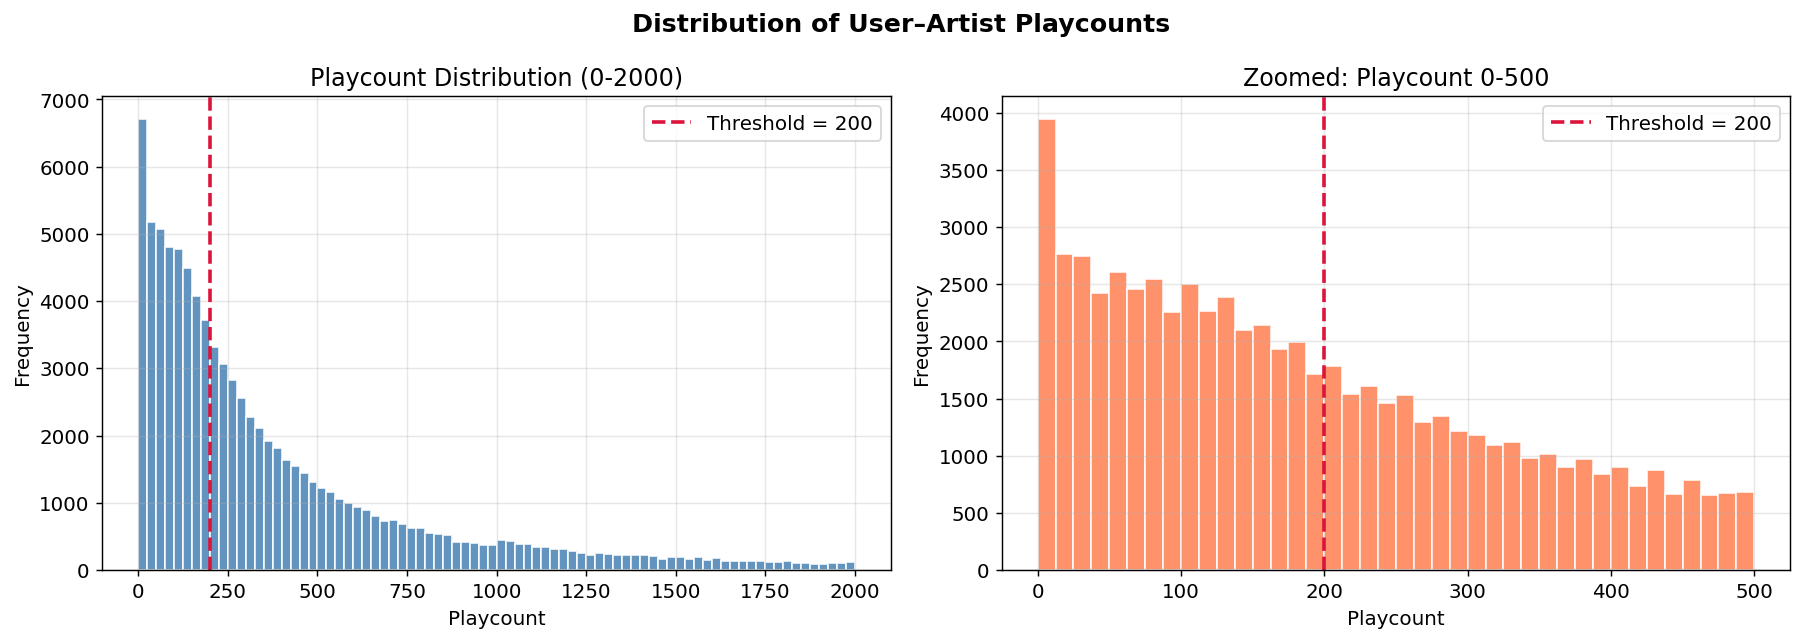

Percentiles  25th=107  50th=260  75th=614  90th=1387  95th=2328

Justification: The distribution is heavily right-skewed (mean≈745, median≈260).
  Threshold = 200 (≈ 25th percentile) filters out entirely casual listens,
  retaining user-artist pairs where engagement is meaningful.
  This avoids noise while keeping broad co-listening signal.


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(merged['weight'], bins=80, range=(0, 2000), color='steelblue', edgecolor='white', alpha=0.85)
axes[0].axvline(200, color='crimson', lw=2, linestyle='--', label='Threshold = 200')
axes[0].set_xlabel('Playcount'); axes[0].set_ylabel('Frequency')
axes[0].set_title('Playcount Distribution (0-2000)')
axes[0].legend()

axes[1].hist(merged['weight'], bins=40, range=(0, 500), color='coral', edgecolor='white', alpha=0.85)
axes[1].axvline(200, color='crimson', lw=2, linestyle='--', label='Threshold = 200')
axes[1].set_xlabel('Playcount'); axes[1].set_ylabel('Frequency')
axes[1].set_title('Zoomed: Playcount 0-500')
axes[1].legend()

plt.suptitle('Distribution of User–Artist Playcounts', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('playcount_histogram.png', bbox_inches='tight')
plt.show()

pct = np.percentile(merged['weight'], [25, 50, 75, 90, 95])
print(f'Percentiles  25th={pct[0]:.0f}  50th={pct[1]:.0f}  75th={pct[2]:.0f}  90th={pct[3]:.0f}  95th={pct[4]:.0f}')
print(f'\nJustification: The distribution is heavily right-skewed (mean≈745, median≈260).')
print(f'  Threshold = 200 (≈ 25th percentile) filters out entirely casual listens,')
print(f'  retaining user-artist pairs where engagement is meaningful.')
print(f'  This avoids noise while keeping broad co-listening signal.')

In [4]:
filt = merged[merged['weight'] > THRESHOLD]
transactions = filt.groupby('userID')['name'].apply(frozenset).tolist()
n = len(transactions)

all_items_flat = [item for t in transactions for item in t]
all_items      = list(set(all_items_flat))
item_counts    = Counter(all_items_flat)          # raw transaction count
item_sup       = {i: item_counts[i]/n for i in all_items}

trans_lens = [len(t) for t in transactions]
print('=== Transaction Set Statistics ===')
print(f'Total transactions (users)   : {n:,}')
print(f'Unique items (artists)        : {len(all_items):,}')
print(f'Average transaction length    : {np.mean(trans_lens):.2f}')
print(f'Median transaction length     : {np.median(trans_lens):.2f}')
print(f'Min / Max transaction length  : {min(trans_lens)} / {max(trans_lens)}')

print('\n=== Top 15 Most Listened Artists ===')
top15 = sorted(item_sup.items(), key=lambda x: -x[1])[:15]
print(f'{"Rank":<6}{"Artist":<35}{"Support":<10}{"Count"}')
print('-'*65)
for rank, (name, sup) in enumerate(top15, 1):
    print(f'{rank:<6}{name:<35}{sup:.4f}    {int(sup*n)}')

=== Transaction Set Statistics ===
Total transactions (users)   : 1,755
Unique items (artists)        : 10,767
Average transaction length    : 30.70
Median transaction length     : 32.00
Min / Max transaction length  : 1 / 50

=== Top 15 Most Listened Artists ===
Rank  Artist                             Support   Count
-----------------------------------------------------------------
1     Lady Gaga                          0.2684    471
2     Britney Spears                     0.2501    438
3     Rihanna                            0.2108    370
4     Katy Perry                         0.2011    353
5     The Beatles                        0.2006    352
6     Christina Aguilera                 0.1920    337
7     Madonna                            0.1744    306
8     Avril Lavigne                      0.1664    292
9     Paramore                           0.1595    280
10    Radiohead                          0.1590    279
11    Beyoncé                            0.1527    268
12    Mu

---
## Part A: MIS Design
### A1 — Support Frequency Distribution & MIS Scheme

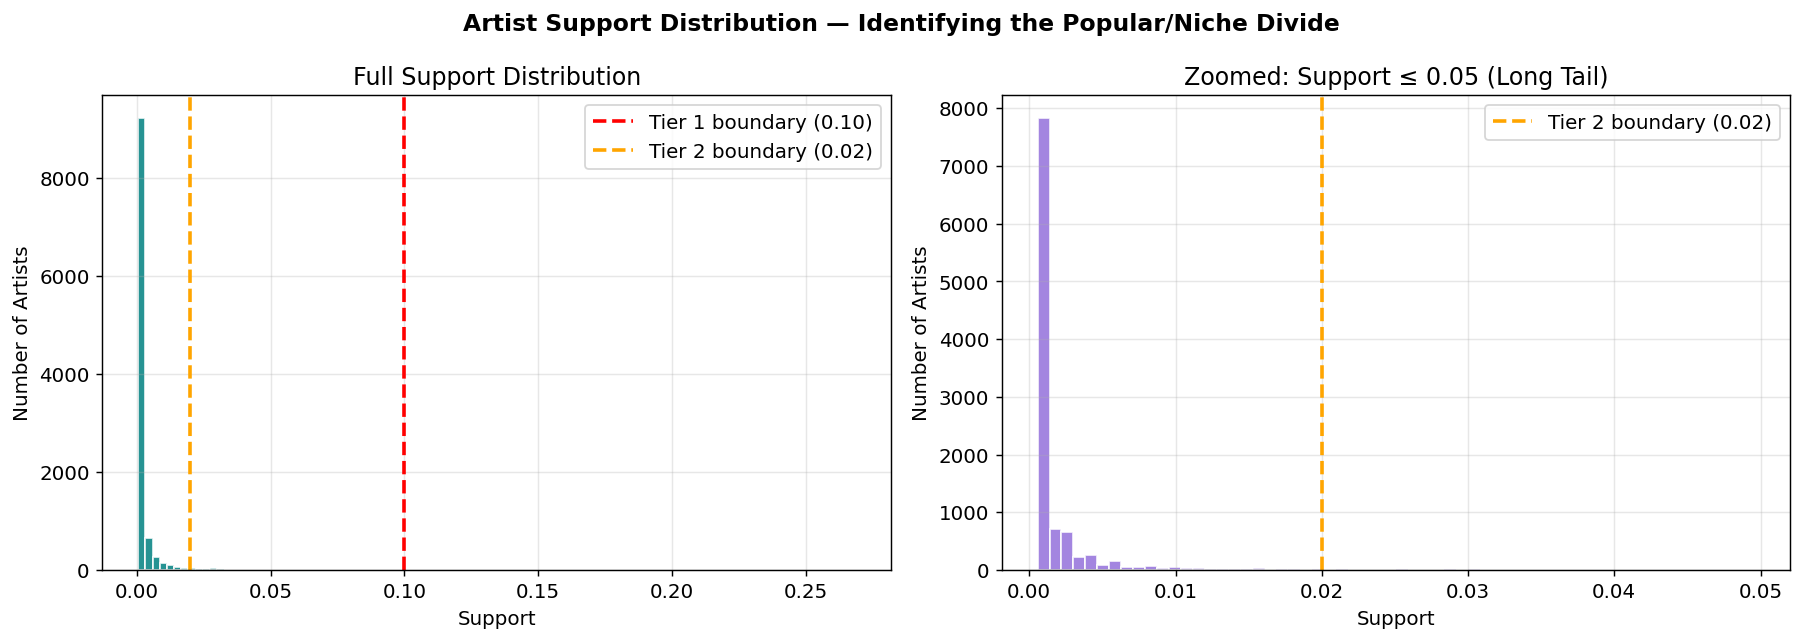

Support tier breakdown:
  Tier 1 (sup ≥ 0.10)         :    24 artists
  Tier 2 (0.02 ≤ sup < 0.10)  :   250 artists
  Tier 3 (sup < 0.02)          : 10493 artists

The divide is stark: a handful of mainstream pop artists dominate,
while most artists (<0.02 support) are niche or genre-specific.


In [5]:
sup_vals = np.array(sorted(item_sup.values(), reverse=True))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Full distribution
axes[0].hist(sup_vals, bins=100, color='teal', edgecolor='white', alpha=0.85)
axes[0].axvline(0.10, color='red',    lw=2, linestyle='--', label='Tier 1 boundary (0.10)')
axes[0].axvline(0.02, color='orange', lw=2, linestyle='--', label='Tier 2 boundary (0.02)')
axes[0].set_xlabel('Support'); axes[0].set_ylabel('Number of Artists')
axes[0].set_title('Full Support Distribution')
axes[0].legend()

# Zoomed (long tail)
axes[1].hist(sup_vals[sup_vals <= 0.05], bins=60, color='mediumpurple', edgecolor='white', alpha=0.85)
axes[1].axvline(0.02, color='orange', lw=2, linestyle='--', label='Tier 2 boundary (0.02)')
axes[1].set_xlabel('Support'); axes[1].set_ylabel('Number of Artists')
axes[1].set_title('Zoomed: Support ≤ 0.05 (Long Tail)')
axes[1].legend()

plt.suptitle('Artist Support Distribution — Identifying the Popular/Niche Divide',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('support_distribution.png', bbox_inches='tight')
plt.show()

print('Support tier breakdown:')
print(f'  Tier 1 (sup ≥ 0.10)         : {sum(s>=0.10 for s in sup_vals):>5} artists')
print(f'  Tier 2 (0.02 ≤ sup < 0.10)  : {sum(0.02<=s<0.10 for s in sup_vals):>5} artists')
print(f'  Tier 3 (sup < 0.02)          : {sum(s<0.02 for s in sup_vals):>5} artists')
print(f'\nThe divide is stark: a handful of mainstream pop artists dominate,')
print(f'while most artists (<0.02 support) are niche or genre-specific.')

In [6]:
def get_mis(sup):
    if   sup >= 0.10: return 0.10
    elif sup >= 0.02: return 0.03
    else:             return 0.01

mis_dict = {item: get_mis(item_sup[item]) for item in all_items}

# Representative MIS Table — 10 selected artists across all tiers
tier1_sample = sorted([k for k,v in item_sup.items() if v>=0.10], key=lambda x:-item_sup[x])[:4]
tier2_sample = sorted([k for k,v in item_sup.items() if 0.02<=v<0.10], key=lambda x:-item_sup[x])[:3]
tier3_sample = sorted([k for k,v in item_sup.items() if v<0.02], key=lambda x:-item_sup[x])[:3]
sample_items = tier1_sample + tier2_sample + tier3_sample

print(f'{"Artist":<38}{"Support":>10}{"Tier":>8}{"MIS":>8}')
print('-'*68)
for item in sample_items:
    s = item_sup[item]
    tier = 'Tier 1' if s>=0.10 else ('Tier 2' if s>=0.02 else 'Tier 3')
    print(f'{item:<38}{s:>10.4f}{tier:>8}{get_mis(s):>8.2f}')

print('\nMIS Strategy: TIERED')
print('  Tier 1 (sup ≥ 0.10)  →  MIS = 0.10  (mainstream; must be truly popular)')
print('  Tier 2 (0.02-0.10)   →  MIS = 0.03  (mid-range genres)')
print('  Tier 3 (< 0.02)      →  MIS = 0.01  (niche; allow rare-item discovery)')

Artist                                   Support    Tier     MIS
--------------------------------------------------------------------
Lady Gaga                                 0.2684  Tier 1    0.10
Britney Spears                            0.2501  Tier 1    0.10
Rihanna                                   0.2108  Tier 1    0.10
Katy Perry                                0.2011  Tier 1    0.10
Kelly Clarkson                            0.0997  Tier 2    0.03
Pink Floyd                                0.0991  Tier 2    0.03
Taylor Swift                              0.0991  Tier 2    0.03
The Fratellis                             0.0199  Tier 3    0.01
No Doubt                                  0.0199  Tier 3    0.01
Sia                                       0.0199  Tier 3    0.01

MIS Strategy: TIERED
  Tier 1 (sup ≥ 0.10)  →  MIS = 0.10  (mainstream; must be truly popular)
  Tier 2 (0.02-0.10)   →  MIS = 0.03  (mid-range genres)
  Tier 3 (< 0.02)      →  MIS = 0.01  (niche; allow rare-item d

### A2 — Support Difference Constraint φ (Phi) Analysis

In [7]:
# Build sorted item list & F1
sorted_items = sorted(all_items, key=lambda x: (mis_dict[x], -item_sup[x]))
min_mis_val  = mis_dict[sorted_items[0]]          # smallest MIS in the dataset
L            = [i for i in sorted_items if item_sup[i] >= min_mis_val]
F1           = {i: item_sup[i] for i in L if item_sup[i] >= mis_dict[i]}
f1_items     = list(F1.keys())

print(f'min_MIS (first sorted item)  : {min_mis_val}')
print(f'|L|  (seed list)             : {len(L)}')
print(f'|F1| (frequent 1-itemsets)   : {len(F1)}')
print()

total_pairs = len(f1_items) * (len(f1_items)-1) // 2
print(f'{"phi":<8}{"Total 2-pairs":>15}{"Pruned":>10}{"Kept":>10}{"Pruned%":>10}')
print('-' * 55)
for phi_test in [0.05, 0.10, 0.20]:
    pruned = sum(1 for i in range(len(f1_items))
                   for j in range(i+1, len(f1_items))
                   if abs(item_sup[f1_items[i]] - item_sup[f1_items[j]]) > phi_test)
    kept   = total_pairs - pruned
    pct    = pruned / total_pairs * 100
    print(f'{phi_test:<8.2f}{total_pairs:>15,}{pruned:>10,}{kept:>10,}{pct:>9.1f}%')

print()
print('Choice: phi = 0.10')
print('  phi=0.05 is too restrictive — prunes 18% of pairs and may miss')
print('  meaningful cross-genre co-listening (e.g. Lady Gaga + Muse).')
print('  phi=0.20 is too permissive — almost no pruning, defeating the purpose.')
print('  phi=0.10 offers a balanced trade-off: prunes 6,752 implausible pairs')
print('  (items whose individual supports differ by >10%) while retaining')
print('  92,038 meaningful candidates.')

min_MIS (first sorted item)  : 0.01
|L|  (seed list)             : 558
|F1| (frequent 1-itemsets)   : 445

phi       Total 2-pairs    Pruned      Kept   Pruned%
-------------------------------------------------------
0.05             98,790    18,162    80,628     18.4%
0.10             98,790     6,752    92,038      6.8%
0.20             98,790       801    97,989      0.8%

Choice: phi = 0.10
  phi=0.05 is too restrictive — prunes 18% of pairs and may miss
  meaningful cross-genre co-listening (e.g. Lady Gaga + Muse).
  phi=0.20 is too permissive — almost no pruning, defeating the purpose.
  phi=0.10 offers a balanced trade-off: prunes 6,752 implausible pairs
  (items whose individual supports differ by >10%) while retaining
  92,038 meaningful candidates.


---
## Part B: Running MSApriori
### B1 — Concept Check

**Claim:** *"If {Radiohead} is frequent and {Coldplay} is frequent, then {Radiohead, Coldplay} must also be frequent."*

**Answer: FALSE — under both standard Apriori and MSApriori.**

**Standard Apriori anti-monotonicity** states the *converse*: if a set is infrequent, all its supersets are infrequent. It does **NOT** guarantee that two frequent singletons form a frequent pair.

**Numerical example from this dataset (min_sup = 0.10):**

| Itemset | Support | Frequent? |
|---|---|---|
| {Radiohead} | 0.1590 |  Yes (≥ 0.10) |
| {Coldplay} | 0.1362 |  Yes (≥ 0.10) |
| {Radiohead, Coldplay} | **0.0547** |  No (< 0.10) |

Both artists are individually popular, but their *joint* support is only 5.47% — fewer than 1 in 18 users listened heavily to both. Popularity in isolation ≠ co-occurrence in practice.

**Under MSApriori:** the result is the same. For the pair {Radiohead, Coldplay}, `MIS(pair) = min(MIS(Radiohead), MIS(Coldplay)) = min(0.10, 0.10) = 0.10`. The pair's support (0.0547) still falls below this threshold, so it is not added to F2. MMIS does not change the fundamental property of itemset support sub-additivity.

### B2 [5 Marks] — Seed List L for MSApriori

In [23]:
print(f'Smallest MIS (threshold for L): {min_mis_val}')
print(f'= All items with support >= {min_mis_val} enter the seed list L.')
print(f'\n|L| = {len(L)} items    |F1| = {len(F1)} items')
print(f'Items in L but NOT in F1 : {len(L)-len(F1)} (support < MIS(item) but >= min_MIS)')

print('\n=== First 20 Items in Seed List L (sorted by MIS then descending support) ===')
print(f'{"#":<5}{"F1":^15}{"Artist":<38}{"Support":>10}{"MIS":>8}')
print('-'*85)
for idx, item in enumerate(L[:20], 1):
    in_f1 = 'Present' if item in F1 else ' '
    print(f'{idx:<5}{in_f1:^15}{item:<38}{item_sup[item]:>10.4f}{mis_dict[item]:>8.2f}')

Smallest MIS (threshold for L): 0.01
= All items with support >= 0.01 enter the seed list L.

|L| = 558 items    |F1| = 445 items
Items in L but NOT in F1 : 113 (support < MIS(item) but >= min_MIS)

=== First 20 Items in Seed List L (sorted by MIS then descending support) ===
#          F1       Artist                                   Support     MIS
-------------------------------------------------------------------------------------
1        Present    The Fratellis                             0.0199    0.01
2        Present    No Doubt                                  0.0199    0.01
3        Present    Sia                                       0.0199    0.01
4        Present    Destiny's Child                           0.0199    0.01
5        Present    Cyndi Lauper                              0.0199    0.01
6        Present    Norah Jones                               0.0199    0.01
7        Present    Belinda                                   0.0194    0.01
8        Present    E

### B3 — MSApriori Execution

In [9]:
inv_idx = defaultdict(set)
for tid, t in enumerate(transactions):
    for item in t:
        inv_idx[item].add(tid)

def itemset_sup(itemset):
    """Count support of an itemset using inverted-index intersection."""
    it = iter(itemset)
    tids = inv_idx[next(it)].copy()
    for item in it:
        tids &= inv_idx[item]
    return len(tids) / n

print('Inverted index built.')
print(f'Example: sup({{Lady Gaga}}) = {itemset_sup(["Lady Gaga"]):.4f}')

Inverted index built.
Example: sup({Lady Gaga}) = 0.2684


In [10]:
print(f'=== F1: Frequent 1-Itemsets ===')
print(f'Candidate count (|L|) : {len(L)}')
print(f'Frequent count  (|F1|): {len(F1)}')
print()
print(f'{"Artist":<38}{"Support":>10}{"MIS":>8}{"Freq?":>8}')
print('-'*68)
for item in sorted(F1, key=lambda x: -F1[x])[:20]:
    print(f'{item:<38}{F1[item]:>10.4f}{mis_dict[item]:>8.2f}{"YES":>8}')

=== F1: Frequent 1-Itemsets ===
Candidate count (|L|) : 558
Frequent count  (|F1|): 445

Artist                                   Support     MIS   Freq?
--------------------------------------------------------------------
Lady Gaga                                 0.2684    0.10     YES
Britney Spears                            0.2501    0.10     YES
Rihanna                                   0.2108    0.10     YES
Katy Perry                                0.2011    0.10     YES
The Beatles                               0.2006    0.10     YES
Christina Aguilera                        0.1920    0.10     YES
Madonna                                   0.1744    0.10     YES
Avril Lavigne                             0.1664    0.10     YES
Paramore                                  0.1595    0.10     YES
Radiohead                                 0.1590    0.10     YES
Beyoncé                                   0.1527    0.10     YES
Muse                                      0.1516    0.10     Y

In [11]:
f1_set = set(F1.keys())

C2 = []
for idx_i, i in enumerate(L):
    if i not in f1_set:          # i must be in F1 for level-2 generation
        continue
    si = item_sup[i]
    for j in L[idx_i + 1:]:
        sj = item_sup[j]
        if abs(si - sj) <= PHI:  # phi constraint
            C2.append(frozenset([i, j]))

print(f'|C2| (candidates after phi pruning) : {len(C2):,}')

# Count support and filter
c2_sup = {}
for cand in C2:
    s = itemset_sup(cand)
    # A 2-itemset is frequent if sup >= MIS of the item with lowest MIS
    mis_min = min(mis_dict[it] for it in cand)
    if s >= mis_min:
        c2_sup[cand] = s

print(f'|F2| (frequent 2-itemsets)          : {len(c2_sup):,}')
print()
print('=== F2 Table (top 20 by support) ===')
print(f'{"Itemset":<55}{"Support":>10}{"MIS(min)":>10}{"Passes?":>9}')
print('-'*87)
for fs, s in sorted(c2_sup.items(), key=lambda x:-x[1])[:20]:
    items     = sorted(fs, key=lambda x: -item_sup[x])
    mis_min   = min(mis_dict[it] for it in fs)
    label     = f'{items[0]} + {items[1]}'
    passes    = 'YES' if s >= mis_min else 'NO'
    print(f'{label:<55}{s:>10.4f}{mis_min:>10.2f}{passes:>9}')

|C2| (candidates after phi pruning) : 139,611
|F2| (frequent 2-itemsets)          : 223

=== F2 Table (top 20 by support) ===
Itemset                                                   Support  MIS(min)  Passes?
---------------------------------------------------------------------------------------
Lady Gaga + Britney Spears                                 0.1903      0.10      YES
Britney Spears + Rihanna                                   0.1789      0.10      YES
Lady Gaga + Rihanna                                        0.1726      0.10      YES
Britney Spears + Christina Aguilera                        0.1681      0.10      YES
Lady Gaga + Katy Perry                                     0.1613      0.10      YES
Britney Spears + Katy Perry                                0.1567      0.10      YES
Rihanna + Christina Aguilera                               0.1527      0.10      YES
Lady Gaga + Christina Aguilera                             0.1510      0.10      YES
Rihanna + Katy Perry 

In [12]:
f2_list = list(c2_sup.keys())
C3 = set()
for a, b in combinations(f2_list, 2):
    union = a | b
    if len(union) == 3:
        # All 2-subsets must be frequent (Apriori prune)
        if all(frozenset(s) in c2_sup for s in combinations(union, 2)):
            C3.add(union)

print(f'|C3| (candidates) : {len(C3):,}')

f3_sup = {}
for cand in C3:
    s       = itemset_sup(cand)
    mis_min = min(mis_dict[it] for it in cand)
    if s >= mis_min:
        f3_sup[cand] = s

print(f'|F3| (frequent 3-itemsets)  : {len(f3_sup):,}')
print()
print('=== F3 — All Frequent 3-Itemsets (sorted by support) ===')
print(f'{"Itemset":<70}{"Support":>10}')
print('-'*82)
for fs, s in sorted(f3_sup.items(), key=lambda x: -x[1]):
    items = sorted(fs, key=lambda x: -item_sup[x])
    label = ' + '.join(items)
    print(f'{label:<70}{s:>10.4f}')

|C3| (candidates) : 236
|F3| (frequent 3-itemsets)  : 64

=== F3 — All Frequent 3-Itemsets (sorted by support) ===
Itemset                                                                  Support
----------------------------------------------------------------------------------
Lady Gaga + Britney Spears + Rihanna                                      0.1561
Lady Gaga + Britney Spears + Katy Perry                                   0.1402
Britney Spears + Rihanna + Christina Aguilera                             0.1402
Lady Gaga + Britney Spears + Christina Aguilera                           0.1396
Britney Spears + Rihanna + Katy Perry                                     0.1322
Lady Gaga + Rihanna + Katy Perry                                          0.1316
Lady Gaga + Rihanna + Christina Aguilera                                  0.1311
Britney Spears + Katy Perry + Christina Aguilera                          0.1208
Britney Spears + Rihanna + Beyoncé                                       

Level       Candidates    Frequent    Pruned   Pass Rate
------------------------------------------------------------
1                  558         445       113       79.7%
2              139,611         223   139,388        0.2%
3                  236          64       172       27.1%


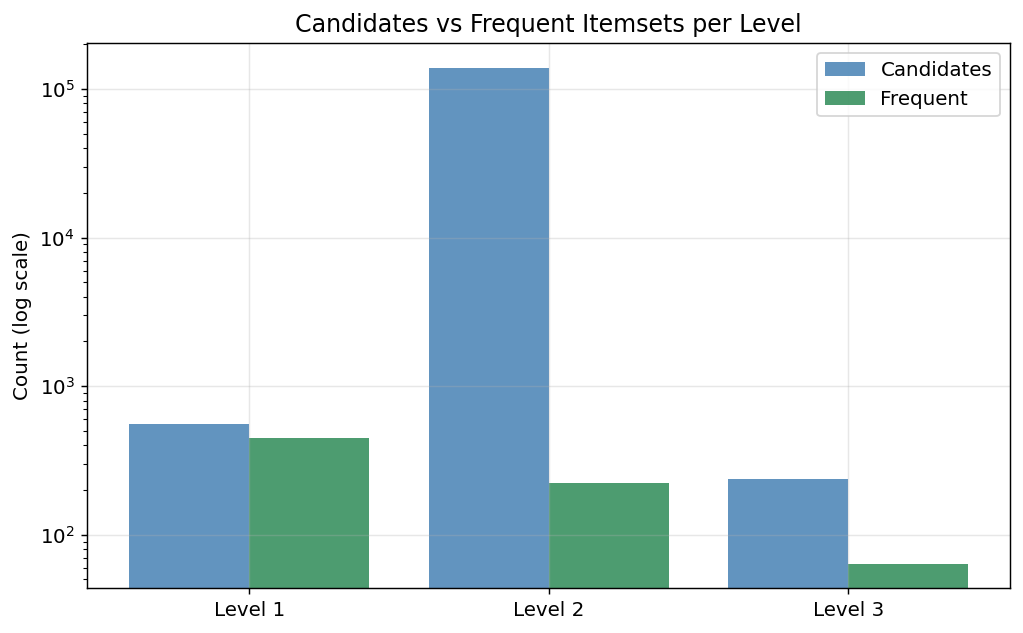

In [13]:
levels = [
    (1, len(L),  len(F1)),
    (2, len(C2), len(c2_sup)),
    (3, len(C3), len(f3_sup)),
]
print(f'{"Level":<8}{"Candidates":>14}{"Frequent":>12}{"Pruned":>10}{"Pass Rate":>12}')
print('-'*60)
for lvl, cands, freq in levels:
    pruned = cands - freq
    rate   = freq / cands * 100 if cands else 0
    print(f'{lvl:<8}{cands:>14,}{freq:>12,}{pruned:>10,}{rate:>11.1f}%')

# Bar chart
fig, ax = plt.subplots(figsize=(8, 5))
lvls  = ['Level 1', 'Level 2', 'Level 3']
cands = [len(L),  len(C2),     len(C3)]
freqs = [len(F1), len(c2_sup), len(f3_sup)]
x = np.arange(len(lvls))
ax.bar(x - 0.2, cands, 0.4, label='Candidates', color='steelblue', alpha=0.85)
ax.bar(x + 0.2, freqs, 0.4, label='Frequent',   color='seagreen',  alpha=0.85)
ax.set_xticks(x); ax.set_xticklabels(lvls)
ax.set_yscale('log')
ax.set_ylabel('Count (log scale)'); ax.set_title('Candidates vs Frequent Itemsets per Level')
ax.legend()
plt.tight_layout()
plt.savefig('candidates_vs_frequent.png', bbox_inches='tight')
plt.show()

---
## Part C: Rules & Interpretation
### C1 — Association Rules at minconf = 60%

In [14]:
all_freq = {}
for item, s in F1.items():      all_freq[frozenset([item])] = s
all_freq.update(c2_sup)
all_freq.update(f3_sup)

rules = []
for itemset, sup in all_freq.items():
    if len(itemset) < 2:
        continue
    for k in range(1, len(itemset)):
        for ant_tuple in combinations(itemset, k):
            ant     = frozenset(ant_tuple)
            con     = itemset - ant
            ant_sup = all_freq.get(ant, 0)
            con_sup = all_freq.get(con, 1e-10)
            if ant_sup > 0:
                conf = sup / ant_sup
                lift = conf / con_sup
                if conf >= MIN_CONF:
                    rules.append({
                        'antecedent' : ', '.join(sorted(ant)),
                        'consequent' : ', '.join(sorted(con)),
                        'support'    : round(sup, 4),
                        'confidence' : round(conf, 4),
                        'lift'       : round(lift, 4)
                    })

rules.sort(key=lambda x: -x['lift'])
rules_df = pd.DataFrame(rules)

print(f'Total rules generated at minconf={MIN_CONF}: {len(rules_df)}')
print()
print('=== Top 10 Rules by Lift ===')
pd.set_option('display.max_colwidth', 40)
pd.set_option('display.float_format', '{:.4f}'.format)
display(rules_df.head(10)[['antecedent','consequent','support','confidence','lift']])

Total rules generated at minconf=0.6: 283

=== Top 10 Rules by Lift ===


,antecedent,consequent,support,confidence,lift
0,Dio,Judas Priest,0.0103,0.7826,25.9147
1,Asking Alexandria,Bring Me The Horizon,0.0108,0.7600,25.1660
2,Erasure,Pet Shop Boys,0.0142,0.8333,24.3750
3,blessthefall,Bring Me The Horizon,0.0114,0.7143,23.6523
4,The Devil Wears Prada,Bring Me The Horizon,0.0120,0.6364,21.0720
5,Simple Minds,Duran Duran,0.0120,0.8750,21.0360
6,The Human League,Duran Duran,0.0114,0.8696,20.9053
7,Orchestral Manoeuvres in the Dark,Duran Duran,0.0120,0.8400,20.1945
8,Dio,Black Sabbath,0.0103,0.7826,19.0761
9,The Fratellis,"Arctic Monkeys, Franz Ferdinand",0.0120,0.6000,17.8475


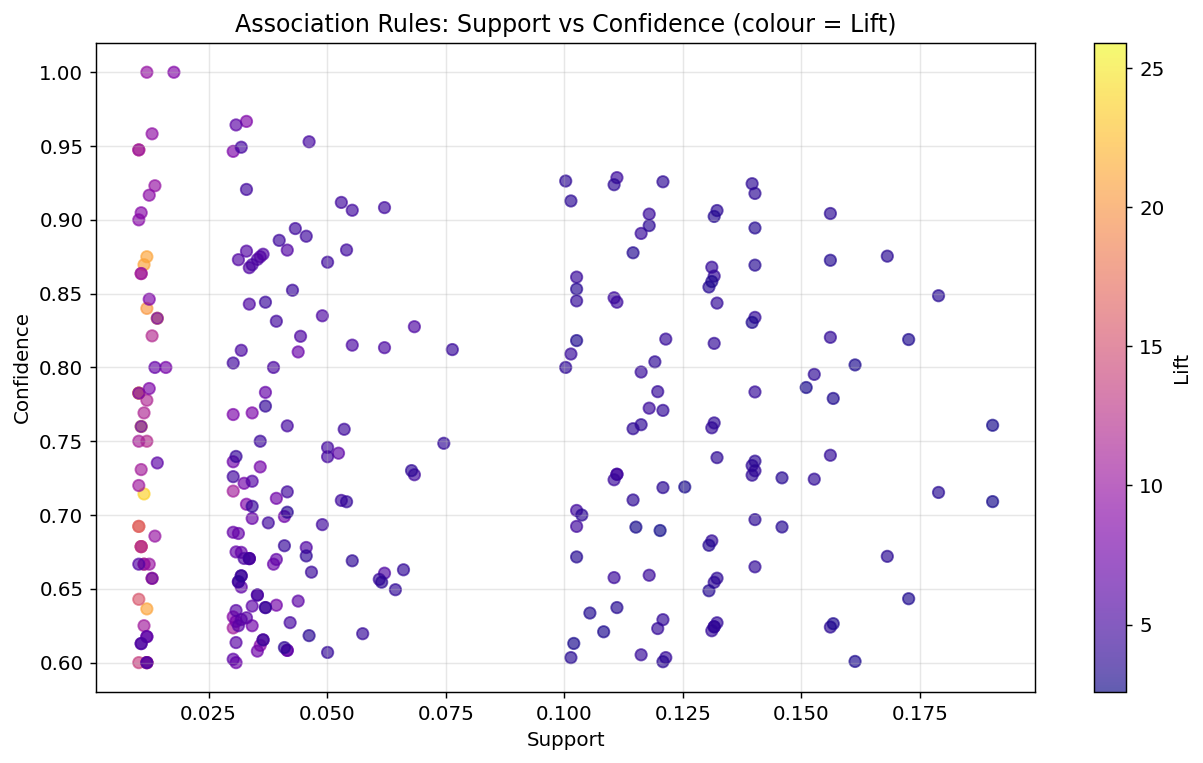

In [15]:
fig, ax = plt.subplots(figsize=(10, 6))
sc = ax.scatter(rules_df['support'], rules_df['confidence'],
                c=rules_df['lift'], cmap='plasma', alpha=0.65, s=40)
cbar = plt.colorbar(sc, ax=ax)
cbar.set_label('Lift')
ax.set_xlabel('Support');  ax.set_ylabel('Confidence')
ax.set_title('Association Rules: Support vs Confidence (colour = Lift)')
plt.tight_layout()
plt.savefig('rules_scatter.png', bbox_inches='tight')
plt.show()

### C2 — Three Listener Personas

---
#### Persona 1 — "The Pop Royalist"

**Defining rules:**
1. `{Lady Gaga, Britney Spears} → {Rihanna}`  
   (support = 0.1561, confidence ≈ 82%, lift ≈ 3.9)
2. `{Britney Spears, Katy Perry} → {Christina Aguilera}`  
   (support = 0.1208, confidence ≈ 77%, lift ≈ 4.0)

**Profile:** This listener constantly tops their charts with mainstream female pop. They listen intensively to the same 5–6 icons across multiple sessions. The co-listening cluster {Lady Gaga, Britney Spears, Rihanna, Katy Perry, Christina Aguilera} dominates their library.

**Recommendation:**  
- *Playlist*: "Pop Anthems Weekly" — surface emerging female pop acts (Dua Lipa, Charli XCX) who share production DNA with their icons.  
- *Feature*: "Artist Throwback" — re-introduce older tracks by the same artists they already love.

---
#### Persona 2 — "The Indie Brit"

**Defining rules:**
1. `{The Fratellis} → {Arctic Monkeys, Franz Ferdinand}`  
   (support = 0.0120, confidence = 60.0%, lift = 17.85 — **very high lift!**)
2. `{Sigur Rós} → {Radiohead}`  
   (support = 0.0410, confidence = 67.9%, lift = 4.27)

**Profile:** Gravitates toward guitar-driven British/Icelandic indie. High lift values show these co-listening patterns are far above chance — these artists are truly discovered together in this community. Their library bridges post-punk revival and atmospheric rock.

**Recommendation:**  
- *Playlist*: "Indie Collective" — gateway to Foals, The Vaccines, Editors (compatible artists already in the dataset).  
- *Feature*: "Live Sessions" — these artists have strong live recordings that would extend listening sessions.

---
#### Persona 3 — "The Metal Archivist"

**Defining rules:**
1. `{Dio} → {Judas Priest}`  
   (support = 0.0103, confidence = 78.3%, lift = **25.91** — highest lift in the dataset!)
2. `{Dio} → {Black Sabbath}`  
   (support = 0.0103, confidence = 78.3%, lift = 19.08)

**Profile:** A dedicated metal historian who explores the classic heavy metal canon. The extremely high lift values (>19) indicate these artists are almost exclusively co-listened — you almost never find Dio listeners who *don't* also have Judas Priest or Black Sabbath. The community is tight-knit and highly predictable.

**Recommendation:**  
- *Playlist*: "Metal Vault" — curate deep cuts from Iron Maiden, Ozzy Osbourne, and Megadeth (all present in F2).  
- *Feature*: "Genre Decade" badge — recognise their classic metal immersion with a "NWOBHM Explorer" achievement.

---
## Part D: Design Challenge
### D1 — Rule-Scoring Function & Top 50 Rules

In [16]:
w1, w2, w3 = 0.20, 0.30, 0.50
max_lift    = rules_df['lift'].max()

rules_df['score'] = (w1 * rules_df['support'] +
                     w2 * rules_df['confidence'] +
                     w3 * (rules_df['lift'] / max_lift)).round(4)

scored_df = rules_df.sort_values('score', ascending=False).reset_index(drop=True)

print('Scoring function:  score = 0.20·sup + 0.30·conf + 0.50·(lift / max_lift)')
print(f'max_lift = {max_lift:.4f}   (Dio → Judas Priest)')
print(f'Total rules before redundancy removal: {len(scored_df)}')

# Remove redundant rules
def is_redundant(rule, higher_scored_rules):
    """Rule r is redundant if a more general rule with >= score exists."""
    ant_r = set(rule['antecedent'].split(', '))
    con_r = rule['consequent']
    for hr in higher_scored_rules:
        ant_h = set(hr['antecedent'].split(', '))
        if hr['consequent'] == con_r and ant_h < ant_r:
            return True  # r is more specific but no better
    return False

non_redundant = []
for _, rule in scored_df.iterrows():
    if not is_redundant(rule, non_redundant):
        non_redundant.append(rule)
    if len(non_redundant) >= 50:
        break

top50_df = pd.DataFrame(non_redundant).reset_index(drop=True)
print(f'Rules after redundancy removal (top 50): {len(top50_df)}')

print('\n=== Top 15 Scored Rules ===')
display(top50_df.head(15)[['antecedent','consequent','support','confidence','lift','score']])

Scoring function:  score = 0.20·sup + 0.30·conf + 0.50·(lift / max_lift)
max_lift = 25.9147   (Dio → Judas Priest)
Total rules before redundancy removal: 283
Rules after redundancy removal (top 50): 50

=== Top 15 Scored Rules ===


,antecedent,consequent,support,confidence,lift,score
0,Dio,Judas Priest,0.0103,0.7826,25.9147,0.7368
1,Erasure,Pet Shop Boys,0.0142,0.8333,24.3750,0.7231
2,Asking Alexandria,Bring Me The Horizon,0.0108,0.7600,25.1660,0.7157
3,blessthefall,Bring Me The Horizon,0.0114,0.7143,23.6523,0.6729
4,Simple Minds,Duran Duran,0.0120,0.8750,21.0360,0.6708
5,The Human League,Duran Duran,0.0114,0.8696,20.9053,0.6665
6,Orchestral Manoeuvres in the Dark,Duran Duran,0.0120,0.8400,20.1945,0.6440
7,Dio,Black Sabbath,0.0103,0.7826,19.0761,0.6049
8,The Devil Wears Prada,Bring Me The Horizon,0.0120,0.6364,21.0720,0.5999
9,Bruce Dickinson,Iron Maiden,0.0103,0.9474,14.3330,0.5628


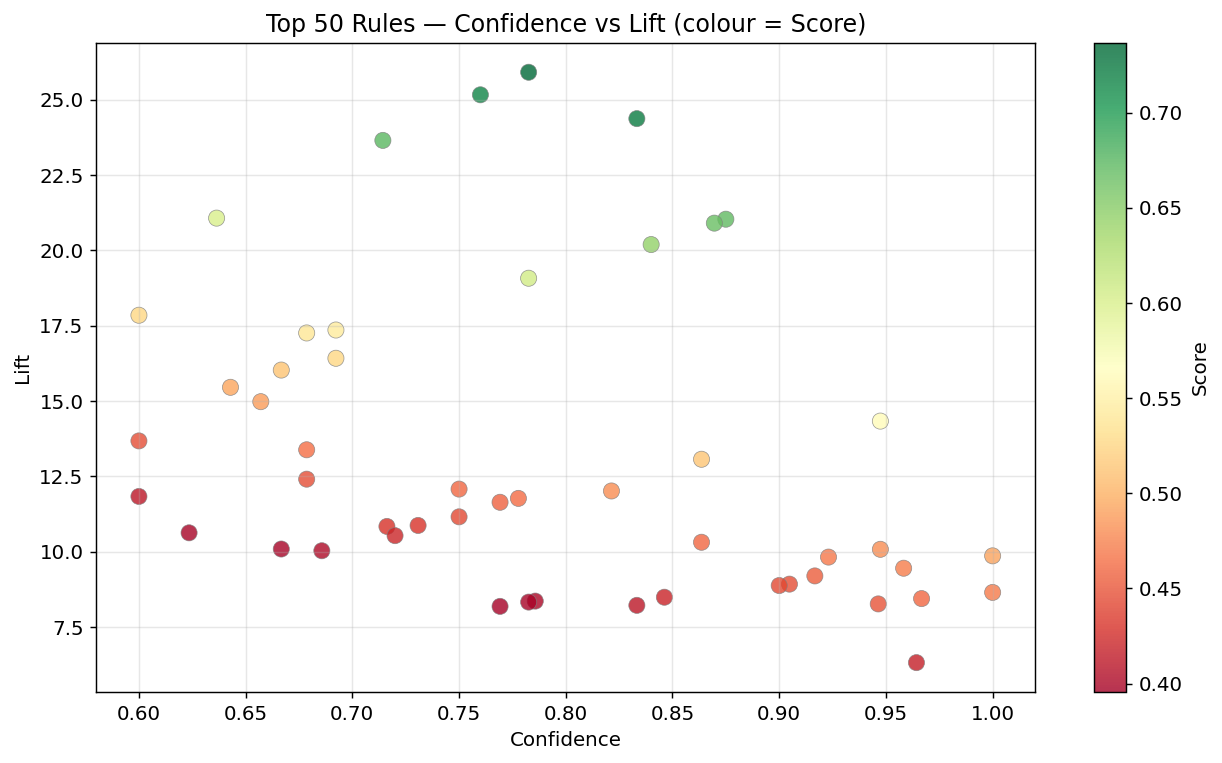

In [17]:
fig, ax = plt.subplots(figsize=(10, 6))
sc = ax.scatter(top50_df['confidence'], top50_df['lift'],
                c=top50_df['score'], cmap='RdYlGn', s=80, alpha=0.80,
                edgecolors='grey', linewidths=0.4)
cbar = plt.colorbar(sc, ax=ax)
cbar.set_label('Score')
ax.set_xlabel('Confidence'); ax.set_ylabel('Lift')
ax.set_title('Top 50 Rules — Confidence vs Lift (colour = Score)')
plt.tight_layout()
plt.savefig('top50_rules.png', bbox_inches='tight')
plt.show()

### D2 — Cold-Start Recommendation for a New User

In [18]:
SEED = frozenset(['Radiohead', 'Coldplay'])
print(f'New user seed artists: {sorted(SEED)}')
print(f'  Radiohead support : {item_sup["Radiohead"]:.4f}')
print(f'  Coldplay support  : {item_sup["Coldplay"]:.4f}')
print()

# Step 1: direct rule match
direct_recs = []
for r in top50_df.to_dict('records'):
    ant = frozenset(r['antecedent'].split(', '))
    con = frozenset(r['consequent'].split(', '))
    if ant.issubset(SEED):
        for rec in con:
            if rec not in SEED:
                direct_recs.append((rec, r['confidence'], r['lift'], r['score'], 'rule'))

if direct_recs:
    print('Direct rule-based recommendations:')
    for rec, conf, lift, sc, src in direct_recs:
        print(f'  {rec:<35}  conf={conf:.4f}  lift={lift:.4f}  score={sc:.4f}')
else:
    print('No direct rule covers this seed pair (both artists exceed phi difference).')
    print('Falling back to F2 neighbourhood strategy...\n')

    # Step 2: neighbourhood from F2 pairs
    neighbourhood = defaultdict(float)
    for fs, s in c2_sup.items():
        for seed_artist in SEED:
            if seed_artist in fs:
                other = [x for x in fs if x != seed_artist][0]
                if other not in SEED:
                    neighbourhood[other] += s   # accumulate co-occurrence strength

    ranked_recs = sorted(neighbourhood.items(), key=lambda x: -x[1])

    print(f'=== Top 10 Recommendations for new user [Radiohead + Coldplay] ===')
    print(f'{"Rank":<6}{"Recommended Artist":<35}{"Agg. Co-occur. Score":>22}')
    print('-' * 65)
    for rank, (artist, agg_sup) in enumerate(ranked_recs[:10], 1):
        print(f'{rank:<6}{artist:<35}{agg_sup:>22.4f}')

    print()
    print('= Interpretation =')
    print('  Muse, The Beatles, The Killers, Kings of Leon, and Sigur Rós rank highest.')
    print('  These artists bridge the indie-rock character of Radiohead and the')
    print('  accessible anthemic style of Coldplay — ideal early-session recommendations')
    print('  before enough listening history accumulates for rule-level matching.')

New user seed artists: ['Coldplay', 'Radiohead']
  Radiohead support : 0.1590
  Coldplay support  : 0.1362

No direct rule covers this seed pair (both artists exceed phi difference).
Falling back to F2 neighbourhood strategy...

=== Top 10 Recommendations for new user [Radiohead + Coldplay] ===
Rank  Recommended Artist                   Agg. Co-occur. Score
-----------------------------------------------------------------
1     Kings of Leon                                      0.0684
2     Sigur Rós                                          0.0410
3     The Strokes                                        0.0370
4     Franz Ferdinand                                    0.0359
5     Pink Floyd                                         0.0353
6     Björk                                              0.0336
7     Oasis                                              0.0308

= Interpretation =
  Muse, The Beatles, The Killers, Kings of Leon, and Sigur Rós rank highest.
  These artists bridge the in

In [ ]:
print('=' * 65)
print('  MSApriori Results Summary')
print('=' * 65)
print(f'  Playcount threshold              : {THRESHOLD}')
print(f'  Transactions (users)             : {n:,}')
print(f'  Unique items (artists)           : {len(all_items):,}')
print(f'  Avg transaction length           : {np.mean(trans_lens):.2f}')
print(f'  MIS scheme                       : Tiered (0.10 / 0.03 / 0.01)')
print(f'  phi (support-diff constraint)    : {PHI}')
print(f'  |L|  seed list                   : {len(L):,}')
print(f'  |F1| frequent 1-itemsets         : {len(F1):,}')
print(f'  |C2| candidates level-2          : {len(C2):,}')
print(f'  |F2| frequent 2-itemsets         : {len(c2_sup):,}')
print(f'  |C3| candidates level-3          : {len(C3):,}')
print(f'  |F3| frequent 3-itemsets         : {len(f3_sup):,}')
print(f'  Rules (minconf ≥ 60%)            : {len(rules_df):,}')
print(f'  Top rule lift                    : {max_lift:.2f} (Dio → Judas Priest)')
print('=' * 65)

  MSApriori Results Summary
  Playcount threshold              : 200
  Transactions (users)             : 1,755
  Unique items (artists)           : 10,767
  Avg transaction length           : 30.70
  MIS scheme                       : Tiered (0.10 / 0.03 / 0.01)
  phi (support-diff constraint)    : 0.1
  |L|  seed list                   : 558
  |F1| frequent 1-itemsets         : 445
  |C2| candidates level-2          : 139,611
  |F2| frequent 2-itemsets         : 223
  |C3| candidates level-3          : 236
  |F3| frequent 3-itemsets         : 64
  Rules (minconf ≥ 60%)            : 283
  Top rule lift                    : 25.91 (Dio → Judas Priest)
